# Benchmark results: polity accuracy

Fifty benchmark individuals (`01_benchmark_creation.ipynb`, `building_scripts/benchmark50_texts.py`). Claude Code agents read each biography blind to Cultura and extracted the most granular place of the early, active and late stage (prompt: `scripts/5-annotations/prompts/biography_polity_extraction.md`). Each place is mapped to the smallest Cliopatria polity holding it over the years Cultura gives the stage. A stage is validated when a benchmark polity matches a Cultura polity directly or through a parent polity, and is compared only when both sides have a polity (`building_scripts/biography_example_validation.py --benchmark50`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

FOLDER = ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark50"
STAGES = {"early": "Early life", "active": "Active life", "late": "Late life"}
people = pl.DataFrame([{"qid": person["qid"], "region": person["claude_estimated_region"], "birth_year": person["cultura_birth_date_year"]}
                       for person in json.loads((FOLDER / "benchmark50_texts.json").read_text(encoding="utf-8"))])
compared = (pl.read_csv(FOLDER / "benchmark50.tsv", separator="\t").join(people, on="qid")
            .filter(pl.col("compared"))
            .with_columns(century=pl.col("birth_year") // 100 + 1))


def accuracy(frame, by, label):
    return (frame.group_by(by).agg(Individuals=pl.col("qid").n_unique(), Compared=pl.len(), Validated=pl.col("validated").sum())
            .select(by, "Individuals", **{"Accuracy (%)": (100 * pl.col("Validated") / pl.col("Compared")).round(1)})
            .rename({by: label}))


def century_name(century):
    number = abs(century) if century > 0 else abs(century) + 1
    suffix = "th" if 10 <= number % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(number % 10, "th")
    return f"{number}{suffix} c." + (" BCE" if century <= 0 else "")

## Accuracy per stage and overall

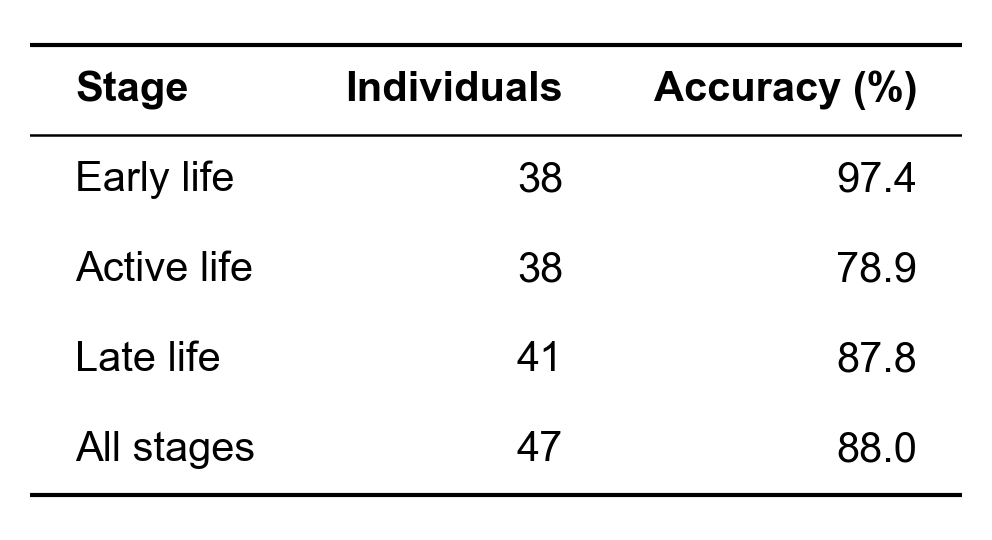

In [2]:
by_stage = accuracy(compared, "stage", "Stage").sort(pl.col("Stage").cast(pl.Enum(list(STAGES)))).with_columns(pl.col("Stage").replace(STAGES))
overall = accuracy(compared.with_columns(stage=pl.lit("All stages")), "stage", "Stage")
show_table(pl.concat([by_stage, overall]), decimals=1, font_size=10)

## Accuracy by century of birth

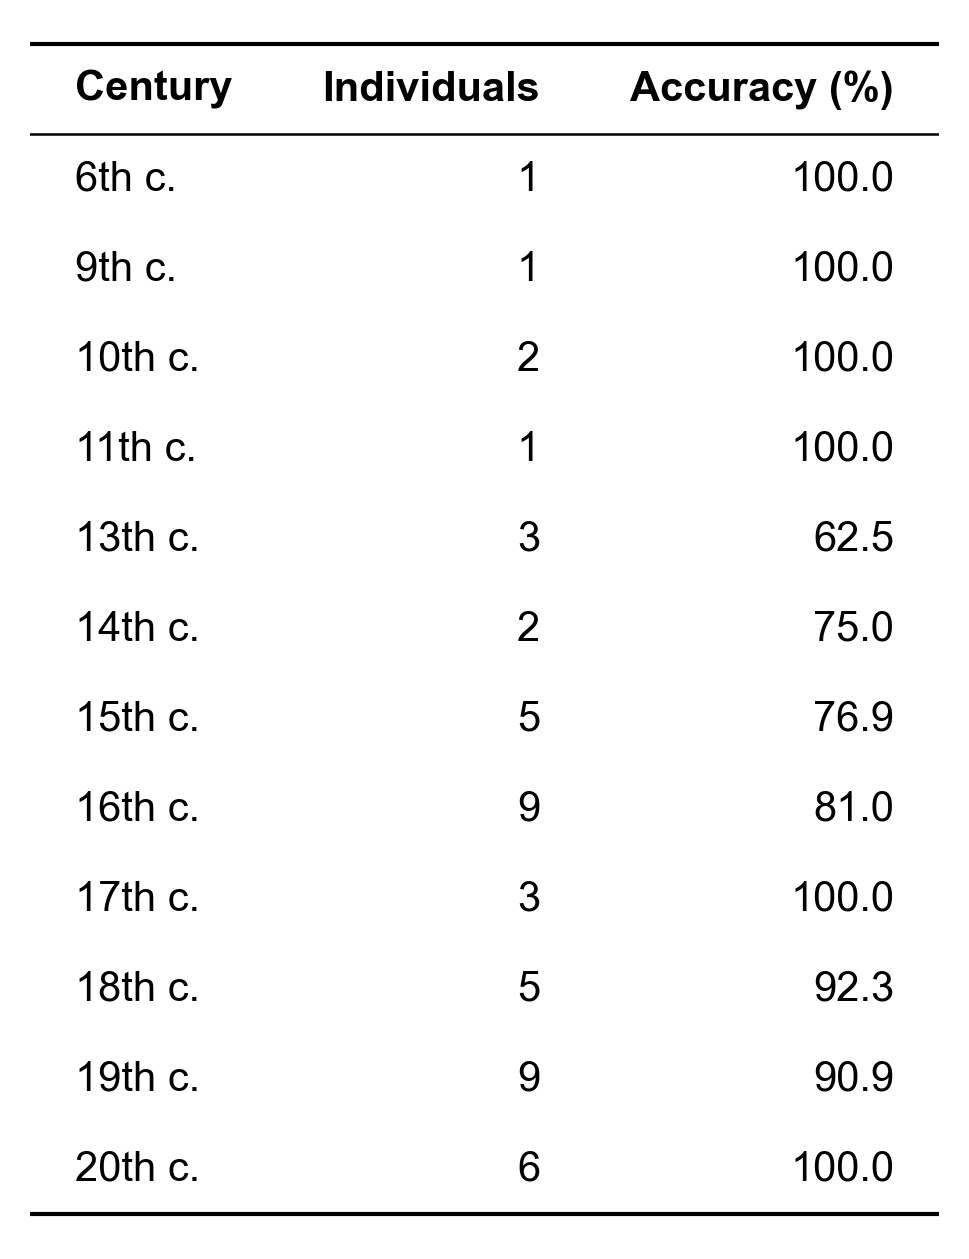

In [3]:
by_century = accuracy(compared, "century", "Century").sort("Century").with_columns(pl.col("Century").map_elements(century_name, return_dtype=pl.String))
show_table(by_century, decimals=1, font_size=10)

## Accuracy by region

Accuracy per stage and overall; a dash is a stage with no comparison in the region. The Sub-Saharan Africa individual has no stage compared.

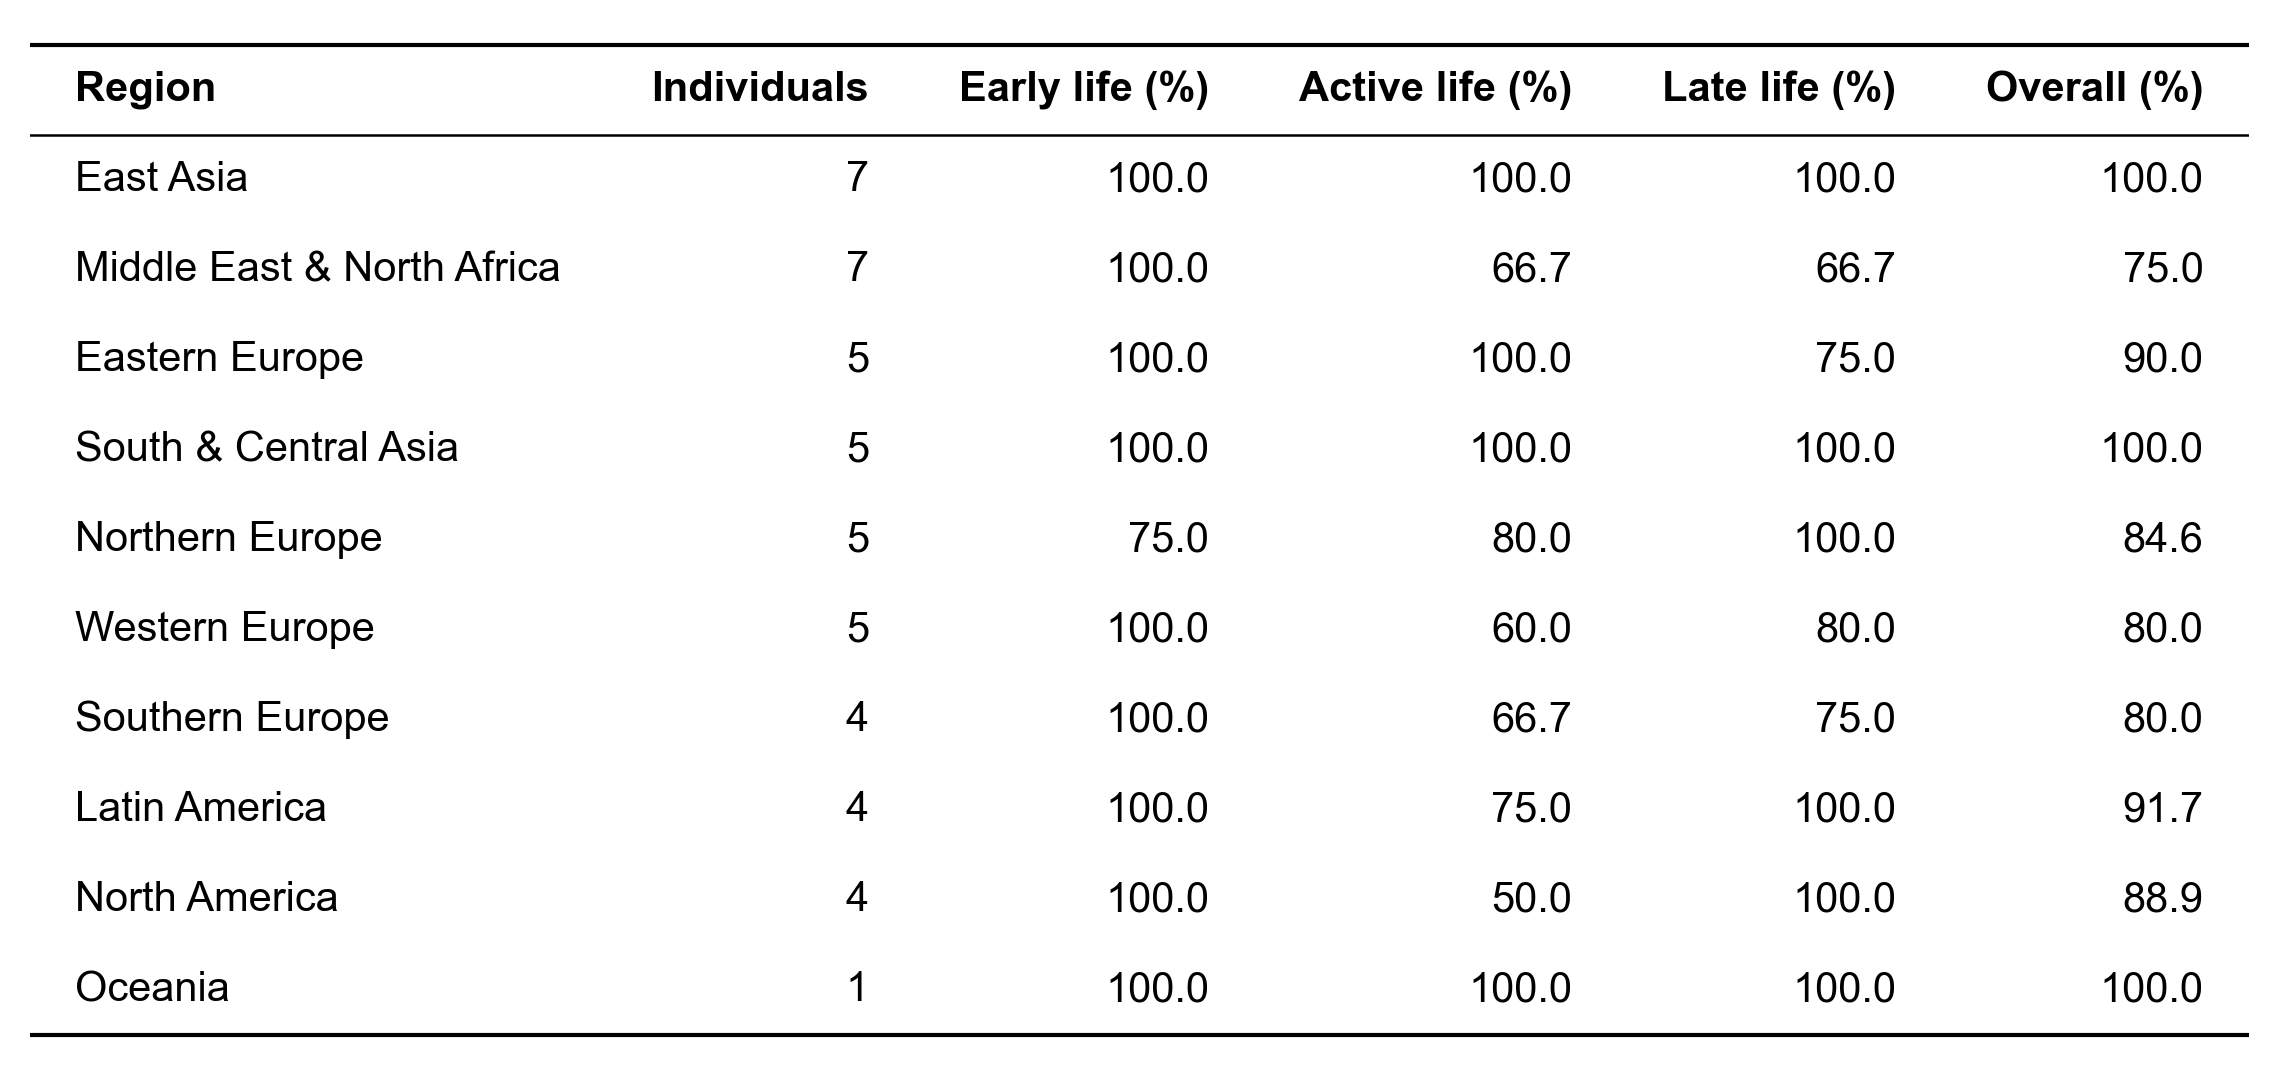

In [4]:
per_stage = (compared.group_by("region", "stage").agg(accuracy=(100 * pl.col("validated").mean()).round(1))
             .pivot(on="stage", index="region", values="accuracy")
             .select("region", *[pl.col(stage).alias(f"{name} (%)") for stage, name in STAGES.items()]))
by_region = (accuracy(compared, "region", "region").join(per_stage, on="region")
             .select(pl.col("region").alias("Region"), "Individuals", *[f"{name} (%)" for name in STAGES.values()], pl.col("Accuracy (%)").alias("Overall (%)"))
             .sort("Individuals", descending=True))
show_table(by_region, decimals=1, font_size=10)